# Building Agentic AI: Essential Design Patterns
#### Data Science Portugal (DSPT) | October 10, 2026
This hands-on workshop walks through the core design patterns for agentic AI, from tool usage to multi-agent collaboration.

**Speaker:** [Ricardo Cardoso Pereira](https://ricardodcpereira.com) is an Assistant Professor (Professor Auxiliar) in the [Department of Informatics Engineering](https://www.uc.pt/fctuc/dei) at the University of Coimbra and a member of [CISUC](https://www.cisuc.uc.pt/en). His research focuses on AI, with interests in deep learning, data-centric AI, fairness in machine learning, and data quality (particularly missing data). He holds a PhD in AI from the University of Coimbra.

**This Jupyter Notebook is available at [tinyurl.com/dspt-agenticai](https://tinyurl.com/dspt-agenticai).**

### Reference
This workshop is based on parts of the book *Agentic Design Patterns: A Hands-On Guide to Building Intelligent Systems* by Antonio Gullí (Springer, 2025).

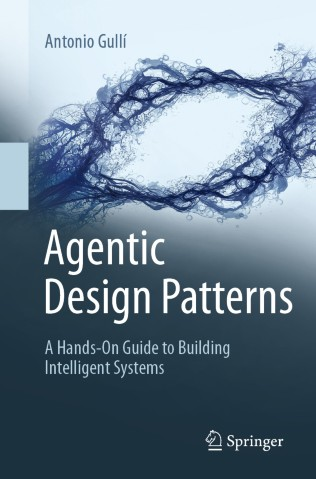

## 1. LLMs vs Agentic AI
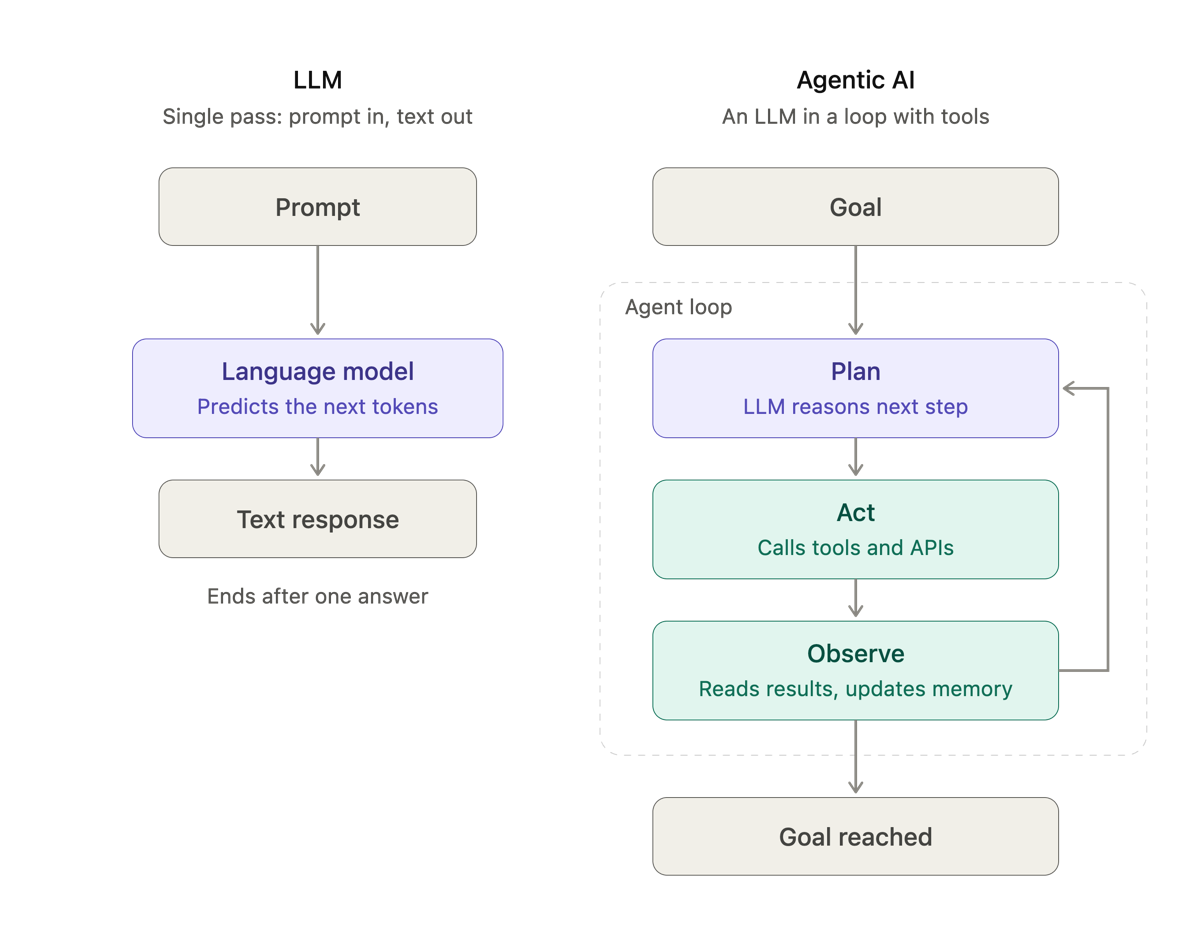

## 2. Setup
Install Ollama (local model server), pull the models, and install Google ADK + LiteLLM.

In [ ]:
!ollama pull gemma4:e4b
!ollama pull granite4:tiny-h

In [ ]:
%pip install -q google-adk==2.11.0 litellm==1.104.0

`llm()` connects ADK to a local Ollama model, and `ask()` runs an agent in a new session and prints all relevant results.

In [ ]:
import json, os, mimetypes, urllib.request, urllib.parse, warnings, logging
from datetime import datetime
from google.adk.agents import Agent
from google.adk.models.lite_llm import LiteLlm
from google.adk.runners import Runner
from google.adk.sessions import InMemorySessionService
from google.genai import types

warnings.filterwarnings("ignore")
logging.getLogger("google_adk").setLevel(logging.ERROR)

def llm(model="gemma4:e4b"):
    return LiteLlm(model=f"openai/{model}", api_base="http://localhost:11434/v1",
                   api_key="ollama", reasoning_effort="none", temperature=0)

In [ ]:
def ask(agent, query, image=None):
    parts = [types.Part(text=query)]
    if image:
        parts.append(types.Part.from_bytes(data=open(image, "rb").read(), 
                                           mime_type=mimetypes.guess_type(image)[0]))
    
    runner = Runner(agent=agent, app_name="workshop_agenticai", 
                    session_service=InMemorySessionService(), 
                    auto_create_session=True)
    
    for event in runner.run(user_id="user", session_id="session", 
                            new_message=types.Content(role="user", parts=parts)):
        for call in event.get_function_calls():
            print(f"[TOOL] [{event.author}] {call.name}({call.args})")
            
        text = "".join(p.text or "" for p in (event.content.parts if event.content else []))
        if event.is_final_response() and text.strip():
            print(f"[ANSWER] [{event.author}] {text.strip()}\n")

## 3. A First Agent

In [ ]:
assistant = Agent(name="assistant", model=llm(), 
                  instruction="You are a helpful assistant. Answer briefly.")

ask(assistant, "What do you know about the University of Coimbra?")

The agent cannot access live data:

In [ ]:
ask(assistant, "What is the current temperature in Coimbra?")

## 4. A Vision Agent
The same kind of agent, using the same multimodal model, can describe images.

In [ ]:
vision_agent = Agent(name="vision_agent", model=llm(),
                     instruction="You are an expert visual analyst. Describe images "
                         "accurately and extract any visible text.")

ask(vision_agent, "Describe this image.", image="cat.jpg")

## 5. Tool Use & Memory Management
**Tool Use:** the agent calls Python functions to act on the world, e.g., a live weather API.

In [ ]:
def current_temp(city: str) -> dict:
    """Returns the current temperature for a city."""
    q = urllib.parse.quote_plus(city.strip())
    gc_url = f"https://geocoding-api.open-meteo.com/v1/search?name={q}&count=1"
    
    with urllib.request.urlopen(gc_url, timeout=8) as r:
        g = json.load(r)
        
    if not g.get("results"):
        return {"error": f"City '{city}' not found."}
    loc = g["results"][0]
    
    wx_url = (f"https://api.open-meteo.com/v1/forecast?latitude={loc['latitude']}"
              f"&longitude={loc['longitude']}&current=temperature_2m&timezone=auto")
    
    with urllib.request.urlopen(wx_url, timeout=8) as r:
        w = json.load(r)
        
    return {"temperature": w["current"]["temperature_2m"], 
            "unit": w["current_units"]["temperature_2m"]}

In [ ]:
print(f"Temperature in Coimbra: {current_temp('Coimbra')}")
print(f"Temperature in Porto: {current_temp('Porto')}")

In [ ]:
weather_agent = Agent(name="weather_agent", model=llm(),
    description="Answers questions about the current temperature in a city.",
    tools=[current_temp],
    instruction="When asked about the current temperature, call 'current_temp'. ")

ask(weather_agent, "What is the current temperature in Coimbra?")
ask(weather_agent, "What is the current temperature in Porto?")

**Memory:** every tool result is saved to a file and loaded into the agent's instructions, so it persists across sessions.

In [ ]:
MEMORY_FILE = "memory.txt"

def save_to_memory(tool, args, tool_context, tool_response):
    with open(MEMORY_FILE, "a") as f:
        f.write(f"[{datetime.now():%Y-%m-%d %H:%M}] {tool.name}({args}) -> {tool_response}\n")

def with_memory(instruction):
    def provider(ctx):
        memory = open(MEMORY_FILE).read() if os.path.exists(MEMORY_FILE) else "(empty)"
        return f"{instruction}\n\nYour long-term memory:\n{memory}"
    return provider

weather_agent = Agent(name="weather_agent", model=llm(),
    description="Answers questions about the current temperature in a city.",
    tools=[current_temp], 
    after_tool_callback=save_to_memory, # or after_agent_callback, etc.
    instruction=with_memory("When asked about the current temperature, call 'current_temp'. "
                            "For questions about the past, answer from your long-term memory."))

ask(weather_agent, "What is the current temperature in Coimbra?")
ask(weather_agent, "What is the current temperature in Porto?")

In [ ]:
print(open(MEMORY_FILE).read())

ask(weather_agent, "Which temperatures have you checked so far, and which city was warmer?")

## 6. Routing, Parallelization & Multi-Agent Systems
**Routing:** a router delegates each request to the most suitable specialist agent (each can use a different model).

In [ ]:
general_agent = Agent(name="general_agent", model=llm("granite4:tiny-h"),
    description="Answers general knowledge questions (history, culture, tourism, ...).",
    instruction="Answer general knowledge questions briefly.")

router = Agent(name="router", model=llm(), sub_agents=[weather_agent, general_agent],
    instruction="You never answer directly: route weather questions to "
                   "weather_agent and all other questions to general_agent.")

ask(router, "How warm is it in Porto right now?")
ask(router, "When was the University of Coimbra founded?")

**Parallelization + Multi-Agent collaboration:** specialists research concurrently, then a writer combines their results.

In [ ]:
from google.adk.agents import SequentialAgent, ParallelAgent

research_team = ParallelAgent(name="research_team", sub_agents=[
    weather_agent.clone({"output_key": "weather",
                         "instruction": "Call 'current_temp' for the city "
                             "mentioned by the user and report the result."}),
    general_agent.clone({"output_key": "places",
                         "instruction": "List the 3 must-see places in the "
                             "city mentioned by the user. Be brief."})])

writer = Agent(name="writer", model=llm(),
    instruction="Write a short visitor briefing (max 80 words) "
                   "using:\nWeather: {weather}\nPlaces: {places}")

visit_agent = SequentialAgent(name="visit_agent",
                              sub_agents=[research_team, writer])

ask(visit_agent, "I am visiting Coimbra today.")

## 7. Planning & Reflection
**Planning:** a planner breaks the goal into steps, and an executor carries them out with tools.

In [ ]:
TASK = ("I have one free day. Choose the warmest city right now among Coimbra, "
            "Porto and Aveiro, and suggest what to do there.")

planner = Agent(name="planner", model=llm(), output_key="plan",
    instruction="Do not solve the task. Write a short numbered plan of steps to "
                    "solve it. You can only use the tool current_temp(city).")

executor = Agent(name="executor", model=llm(), tools=[current_temp], output_key="draft",
    instruction="Execute this plan step by step using your tools, then write the "
                     "final answer for the user:\n{plan}")

planning_agent = SequentialAgent(name="planning_agent", sub_agents=[planner, executor])

ask(planning_agent, TASK)

**Reflection:** a critic reviews the draft and a reviser improves it, looping until the critic approves or *max_iterations* is reached.

In [ ]:
from google.adk.agents import LoopAgent
from google.adk.tools import exit_loop

critic = Agent(name="critic", model=llm(), output_key="feedback", tools=[exit_loop],
    instruction=("You are a strict reviewer. Check this answer:\n{draft}\n\n"
                 "Requirements: (1) lists the temperature of each city; "
                 "(2) names the warmest city; "
                 "(3) suggests exactly 3 activities as a bulleted list; "
                 "(4) ends with a clothing tip for that temperature.\n"
                 "If ALL are met, call the exit_loop tool. Otherwise, explain "
                 "briefly how to fix each failed requirement."))

reviser = Agent(name="reviser", model=llm(), output_key="draft",
    instruction="Rewrite the answer below applying this feedback:\n{feedback}\n\n"
                "Output only the new answer.\n\nAnswer:\n{draft}")

reflection_loop = LoopAgent(name="reflection_loop", max_iterations=3,
                            sub_agents=[critic, reviser])

trip_agent = SequentialAgent(name="trip_agent", 
                             sub_agents=[planning_agent, reflection_loop])

ask(trip_agent, TASK)